In [14]:
!pip install nltk textblob scikit-learn wordcloud matplotlib tensorflow -q

# Lab Assignment 10 

Q1.  Write a unique paragraph (5-6 sentences) about your favorite topic (e.g., sports, 
technology, food, books, etc.). 
1. Convert text to lowercase and remove punctua on using re. 
2. Tokenize the text into words and sentences. 
3. Split using split() and word_tokenize() and compare how Python split and NLTK’s 
word_tokenize() differ. 
4. Remove stopwords (using NLTK's stopwords list). 
5. Display word frequency distribu on (excluding stopwords).

In [15]:
import re
import nltk
from nltk import FreqDist
from nltk.corpus import stopwords
from nltk.tokenize import sent_tokenize, word_tokenize

nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)

paragraph = """Basketball is my favorite sport. I enjoy playing basketball with my friends after class. 
We practice passing, shooting, and dribbling before a game. I don't always score, but I like helping my team. 
Fast games keep me active and make me think quickly. Playing basketball always puts me in a good mood."""

clean_text = re.sub(r"[^\w\s]", " ", paragraph.lower())
sentences = sent_tokenize(paragraph)
words = word_tokenize(clean_text)

print("Clean text:", " ".join(clean_text.split()))
print("Sentences:", sentences)
print("Words:", words)
print("Using split():", paragraph.split())
print("Using word_tokenize():", word_tokenize(paragraph))

stop_words = set(stopwords.words("english"))
filtered_words = [word for word in words if word not in stop_words]
frequency = FreqDist(filtered_words)

print("Words without stopwords:", filtered_words)
print("Word frequencies:", frequency.most_common())

Clean text: basketball is my favorite sport i enjoy playing basketball with my friends after class we practice passing shooting and dribbling before a game i don t always score but i like helping my team fast games keep me active and make me think quickly playing basketball always puts me in a good mood
Sentences: ['Basketball is my favorite sport.', 'I enjoy playing basketball with my friends after class.', 'We practice passing, shooting, and dribbling before a game.', "I don't always score, but I like helping my team.", 'Fast games keep me active and make me think quickly.', 'Playing basketball always puts me in a good mood.']
Words: ['basketball', 'is', 'my', 'favorite', 'sport', 'i', 'enjoy', 'playing', 'basketball', 'with', 'my', 'friends', 'after', 'class', 'we', 'practice', 'passing', 'shooting', 'and', 'dribbling', 'before', 'a', 'game', 'i', 'don', 't', 'always', 'score', 'but', 'i', 'like', 'helping', 'my', 'team', 'fast', 'games', 'keep', 'me', 'active', 'and', 'make', 'me',

Q2. Using the same paragraph from Q1: 
1. Extract all words with only alphabets using re.findall() 
2. Remove stop words using NLTK’s stopword list 
3. Perform stemming with PorterStemmer 
4. Perform lemma za on with WordNetLemma zer 
5. Compare the stemmed and lemma zed outputs and explain when you’d prefer one over 
the other. 

In [16]:
from nltk.stem import PorterStemmer, WordNetLemmatizer

nltk.download("wordnet", quiet=True)
nltk.download("averaged_perceptron_tagger_eng", quiet=True)

alphabet_words = re.findall(r"[a-zA-Z]+", paragraph.lower())
filtered_words = [word for word in alphabet_words if word not in stop_words]

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()
wordnet_tags = {"J": "a", "V": "v", "N": "n", "R": "r"}

tagged_words = nltk.pos_tag(alphabet_words)

print("Alphabetic words:", alphabet_words)
print("Words without stopwords:", filtered_words)

print(f"{'Word':<15}{'Stem':<15}{'Lemma'}")
for word, tag in tagged_words:
    if word not in stop_words:
        stem = stemmer.stem(word)
        lemma = lemmatizer.lemmatize(word, wordnet_tags.get(tag[0], "n"))
        print(f"{word:<15}{stem:<15}{lemma}")


# Stemming truncate word endings and may produce a non-dictionary form.
# Lemmatization returns a meaningful dictionary form (lemma).
# Stemming is useful when speed and broad matching matter.
# lemmatization is preferable when readable, linguistically meaningful words matter.

Alphabetic words: ['basketball', 'is', 'my', 'favorite', 'sport', 'i', 'enjoy', 'playing', 'basketball', 'with', 'my', 'friends', 'after', 'class', 'we', 'practice', 'passing', 'shooting', 'and', 'dribbling', 'before', 'a', 'game', 'i', 'don', 't', 'always', 'score', 'but', 'i', 'like', 'helping', 'my', 'team', 'fast', 'games', 'keep', 'me', 'active', 'and', 'make', 'me', 'think', 'quickly', 'playing', 'basketball', 'always', 'puts', 'me', 'in', 'a', 'good', 'mood']
Words without stopwords: ['basketball', 'favorite', 'sport', 'enjoy', 'playing', 'basketball', 'friends', 'class', 'practice', 'passing', 'shooting', 'dribbling', 'game', 'always', 'score', 'like', 'helping', 'team', 'fast', 'games', 'keep', 'active', 'make', 'think', 'quickly', 'playing', 'basketball', 'always', 'puts', 'good', 'mood']
Word           Stem           Lemma
basketball     basketbal      basketball
favorite       favorit        favorite
sport          sport          sport
enjoy          enjoy          enjoy
pl

Q3. Choose 3 short texts of your own (e.g., different news headlines, product reviews). 
1. Use CountVectorizer to generate the Bag of Words representa on. 
2. Use TfidfVectorizer to compute TF-IDF scores. 
3. Print and interpret the top 3 keywords from each text using TF-IDF.

In [17]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = [
    "The phone has a bright screen, and the screen is easy to read outdoors.",
    "The laptop has a comfortable keyboard, and the keyboard feels good for typing.",
    "The headphones have clear sound, and the sound stays clear at high volume."
]

count_vectorizer = CountVectorizer(stop_words="english")
counts = count_vectorizer.fit_transform(texts)

bow_table = pd.DataFrame(
    counts.toarray(),
    columns=count_vectorizer.get_feature_names_out(),
    index=["Phone", "Laptop", "Headphones"]
)
print("Bag of Words")
print(bow_table.to_string())

tfidf_vectorizer = TfidfVectorizer(stop_words="english")
tfidf = tfidf_vectorizer.fit_transform(texts)
terms = tfidf_vectorizer.get_feature_names_out()

tfidf_table = pd.DataFrame(
    tfidf.toarray(),
    columns=terms,
    index=bow_table.index
)
print("\nTF-IDF scores")
print(tfidf_table.round(3).to_string())

for name, scores in zip(bow_table.index, tfidf.toarray()):
    top_indices = sorted(
        range(len(terms)),
        key=lambda i: (-scores[i], terms[i])
    )[:3]

    print(f"\n{name}")
    for i in top_indices:
        print(f"{terms[i]}: {scores[i]:.3f}")

Bag of Words
            bright  clear  comfortable  easy  feels  good  headphones  high  keyboard  laptop  outdoors  phone  read  screen  sound  stays  typing  volume
Phone            1      0            0     1      0     0           0     0         0       0         1      1     1       2      0      0       0       0
Laptop           0      0            1     0      1     1           0     0         2       1         0      0     0       0      0      0       1       0
Headphones       0      2            0     0      0     0           1     1         0       0         0      0     0       0      2      1       0       1

TF-IDF scores
            bright  clear  comfortable   easy  feels   good  headphones   high  keyboard  laptop  outdoors  phone   read  screen  sound  stays  typing  volume
Phone        0.333  0.000        0.000  0.333  0.000  0.000       0.000  0.000     0.000   0.000     0.333  0.333  0.333   0.667  0.000  0.000   0.000   0.000
Laptop       0.000  0.000        0

Q4. Write 2 short texts (4–6 lines each) describing two different technologies (e.g., AI vs 
Blockchain). 
1. Preprocess and tokenize both texts. 
2. Calculate:
 
a. Jaccard Similarity using sets 

b. Cosine Similarity using TfidfVectorizer + cosine_similarity() 

c. Analyze which similarity metric gives be er insights in your case. 

In [18]:
from sklearn.metrics.pairwise import cosine_similarity

ai_text = """Artificial intelligence uses data to learn patterns.
AI systems use data to make predictions.
Machine learning models improve with more examples.
Hospitals use AI systems to support diagnosis."""

blockchain_text = """Blockchain stores data in linked blocks.
Blockchain systems record transactions across a network.
The network keeps copies of transaction data.
Cryptography helps verify records and detect changes."""

ai_words = [
    word for word in re.findall(r"[a-z]+", ai_text.lower())
    if word not in stop_words
]
blockchain_words = [
    word for word in re.findall(r"[a-z]+", blockchain_text.lower())
    if word not in stop_words
]

print("AI tokens:", ai_words)
print("Blockchain tokens:", blockchain_words)

ai_set = set(ai_words)
blockchain_set = set(blockchain_words)
shared_words = ai_set & blockchain_set

jaccard = len(shared_words) / len(ai_set | blockchain_set)

vectorizer = TfidfVectorizer()
vectors = vectorizer.fit_transform([
    " ".join(ai_words),
    " ".join(blockchain_words)
])
cosine = cosine_similarity(vectors[0], vectors[1])[0, 0]

print("Shared words:", sorted(shared_words))
print("Jaccard similarity:", round(jaccard, 4))
print("Cosine similarity:", round(cosine, 4))


#The exact shared words are data and systems.
#  Jaccard counts each shared word once. 
# TF-IDF cosine similarity also accounts for repetition and gives words that occur in both texts lower IDF weights than words unique to one text. 
# I would use Jaccard here because the question is how much vocabulary two short descriptions share, and the two matching words make the score easy to explain.

AI tokens: ['artificial', 'intelligence', 'uses', 'data', 'learn', 'patterns', 'ai', 'systems', 'use', 'data', 'make', 'predictions', 'machine', 'learning', 'models', 'improve', 'examples', 'hospitals', 'use', 'ai', 'systems', 'support', 'diagnosis']
Blockchain tokens: ['blockchain', 'stores', 'data', 'linked', 'blocks', 'blockchain', 'systems', 'record', 'transactions', 'across', 'network', 'network', 'keeps', 'copies', 'transaction', 'data', 'cryptography', 'helps', 'verify', 'records', 'detect', 'changes']
Shared words: ['data', 'systems']
Jaccard similarity: 0.0556
Cosine similarity: 0.1156


Q5. Write a short review for a product or service. 
1. Use TextBlob or VADER to find polarity & subjec vity for each review. 
2. Classify reviews into Posi ve / Nega ve / Neutral. 
3. Create a word cloud using the wordcloud library for all posi ve reviews.

These headphones are excellent. The sound is clear and the ear cushions are comfortable.
Polarity: 0.475
Subjectivity: 0.646
Sentiment: Positive

The headphones have terrible sound and the ear cushions are uncomfortable.
Polarity: -0.367
Subjectivity: 0.8
Sentiment: Negative

The box contains headphones, a charging cable, and a user manual.
Polarity: 0.0
Subjectivity: 0.0
Sentiment: Neutral



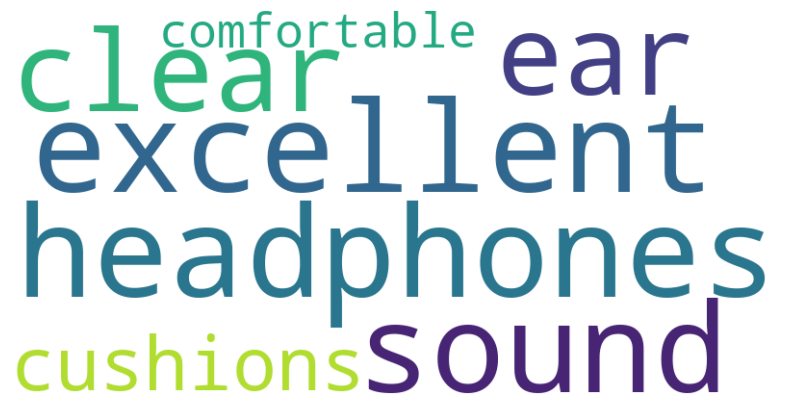

In [19]:
import matplotlib.pyplot as plt
from textblob import TextBlob
from wordcloud import WordCloud

reviews = [
    "These headphones are excellent. The sound is clear and the ear cushions are comfortable.",
    "The headphones have terrible sound and the ear cushions are uncomfortable.",
    "The box contains headphones, a charging cable, and a user manual."
]

positive_reviews = []

for review in reviews:
    polarity, subjectivity = TextBlob(review).sentiment

    if polarity > 0:
        label = "Positive"
        positive_reviews.append(review)
    elif polarity < 0:
        label = "Negative"
    else:
        label = "Neutral"

    print(review)
    print("Polarity:", round(polarity, 3))
    print("Subjectivity:", round(subjectivity, 3))
    print("Sentiment:", label)
    print()

if positive_reviews:
    cloud = WordCloud(
        width=800,
        height=400,
        background_color="white"
    ).generate(" ".join(positive_reviews))

    plt.figure(figsize=(10, 5))
    plt.imshow(cloud, interpolation="bilinear")
    plt.axis("off")
    plt.show()

Q6. Choose your own paragraph (~100 words) as training data. 
1. Tokenize text using Tokenizer() from keras.preprocessing.text 
2. Create input sequences and build a simple LSTM or Dense model 
3. Train the model and generate 2–3 new lines of text star ng from any seed word you 
provide.

In [20]:
import numpy as np
import tensorflow as tf

try:
    from keras.preprocessing.text import Tokenizer
except ImportError:
    from tensorflow.keras.preprocessing.text import Tokenizer

from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense

tf.keras.utils.set_random_seed(42)
rng = np.random.default_rng(42)

training_text = """Basketball brings my friends together after college.
Basketball practice starts with simple passes and easy shots.
Our team runs across the court and shares the ball.
Our team talks during practice and helps each player improve.
A good pass gives another player a chance to score.
A good shot needs balance and a little patience.
The game moves quickly when everyone trusts their teammates.
The game feels better when both teams play fairly.
After practice we sit near the court and talk.
After practice we make plans for another game the next day."""

tokenizer = Tokenizer()
tokenizer.fit_on_texts(training_text.splitlines())

sequences = []
for line in training_text.splitlines():
    tokens = tokenizer.texts_to_sequences([line])[0]
    for end in range(2, len(tokens) + 1):
        sequences.append(tokens[:end])

max_length = max(len(sequence) for sequence in sequences)
sequences = pad_sequences(sequences, maxlen=max_length, padding="pre")

X = sequences[:, :-1]
y = sequences[:, -1]
vocab_size = len(tokenizer.word_index) + 1

model = Sequential([
    Input(shape=(max_length - 1,)),
    Embedding(vocab_size, 32, mask_zero=True),
    LSTM(64),
    Dense(vocab_size, activation="softmax")
])

model.compile(optimizer="adam", loss="sparse_categorical_crossentropy")
model.fit(X, y, epochs=100, batch_size=8, verbose=0)

def generate_line(seed, words_to_add):
    text = seed

    for _ in range(words_to_add):
        tokens = tokenizer.texts_to_sequences([text])
        tokens = pad_sequences(
            tokens,
            maxlen=max_length - 1,
            padding="pre",
            truncating="pre"
        )
        probabilities = model.predict(tokens, verbose=0)[0]
        top_words = np.argsort(probabilities[1:])[-3:] + 1
        weights = probabilities[top_words].astype(float)
        weights /= weights.sum()

        next_id = rng.choice(top_words, p=weights)
        text += " " + tokenizer.index_word[next_id]

    return text.capitalize() + "."

for seed in ["basketball", "our", "after"]:
    print(generate_line(seed, 7))

Basketball brings my friends together together after college.
Our team during during practice and helps each.
After practice we make sit the court and.
